In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [21]:
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df =pd.read_csv(url)

print(df.shape)
df.head()

(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [22]:
print(df.isnull().sum())
print(df["Survived"].value_counts(normalize=True))

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64
Survived
0    0.616162
1    0.383838
Name: proportion, dtype: float64


In [23]:
df = df.drop(columns=["PassengerId", "Name", "Ticket", "Cabin"])



In [24]:
df["Age"] = df["Age"].fillna(df["Age"].median())
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

print(df.isnull().sum())
df.head()

#i: Eksik veri işlenmezse çoğu model çalışmaz. Az eksik varsa doldurulur (sayısalsa medyan, kategorikse mod), çok eksik varsa sütun silinir. Satır silmek veri kaybına yol açar. bu yüzden yaşın medianını alıp bunu boş değerleere atıyoruz

Survived    0
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


In [25]:
df["Sex"] = df["Sex"].map({"male": 0, "female": 1})
df= pd.get_dummies(df, columns=["Embarked"],drop_first=True,dtype=int)  #embarked de 3 değer olduğu için  "get_dumnies"ile 0/1 sütunlarına böler
df.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_Q,Embarked_S
0,0,3,0,22.0,1,0,7.2500,0,1
1,1,1,1,38.0,1,0,71.2833,0,0
2,1,3,1,26.0,0,0,7.9250,0,1
3,1,1,1,35.0,1,0,53.1000,0,1
4,0,3,0,35.0,0,0,8.0500,0,1


In [26]:
from sklearn.model_selection import train_test_split

X= df.drop(columns = ["Survived"])
y = df["Survived"]

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30,stratify=y, random_state=42)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42)

print(X.shape)
print(len(X_train),len(X_val),len(X_test))

(891, 8)
623 134 134


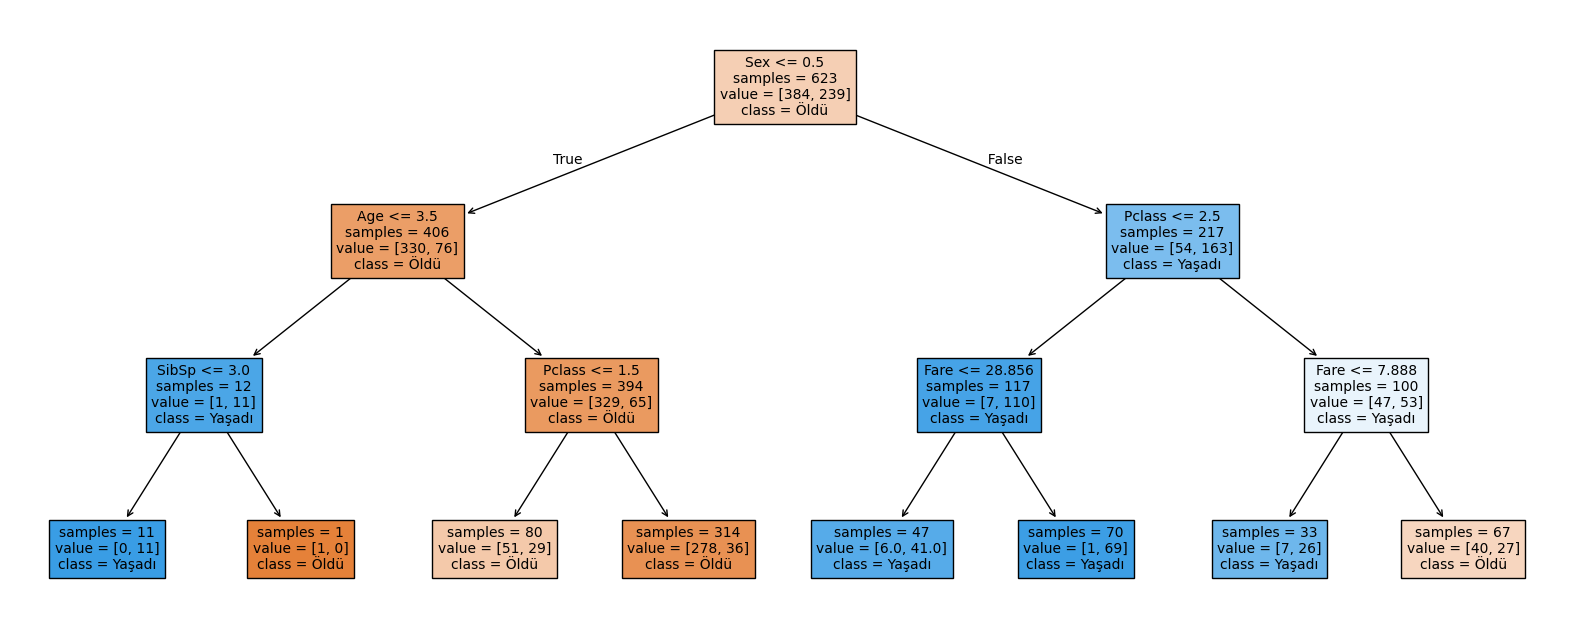

In [27]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

agac = DecisionTreeClassifier(max_depth=3,random_state=42)
agac.fit(X_train,y_train)


plt.figure(figsize=(20,8))
plot_tree(agac,filled=True,feature_names=X.columns,class_names= ["Öldü","Yaşadı"],impurity= False,fontsize=10)

plt.show()

In [28]:
from sklearn.metrics import accuracy_score

for d in [1,2,3,4,5,6,7,8,9]:
  model = DecisionTreeClassifier(max_depth=d,random_state=42)
  model.fit(X_train,y_train)


  train_cc = accuracy_score(y_train,model.predict(X_train))
  val_cc = accuracy_score(y_val,model.predict(X_val))

  print(f"max_depth={d} | train_cc: {train_cc:.4f} | val_cc: {val_cc:.4f}")





max_depth=1 | train_cc: 0.7913 | val_cc: 0.8134
max_depth=2 | train_cc: 0.8074 | val_cc: 0.7985
max_depth=3 | train_cc: 0.8299 | val_cc: 0.8358
max_depth=4 | train_cc: 0.8459 | val_cc: 0.8284
max_depth=5 | train_cc: 0.8636 | val_cc: 0.8209
max_depth=6 | train_cc: 0.8796 | val_cc: 0.8433
max_depth=7 | train_cc: 0.8876 | val_cc: 0.8358
max_depth=8 | train_cc: 0.9101 | val_cc: 0.8134
max_depth=9 | train_cc: 0.9294 | val_cc: 0.7910


In [29]:
from sklearn.ensemble import RandomForestClassifier

tek_agac = DecisionTreeClassifier(max_depth=5,random_state=42)
tek_agac.fit(X_train,y_train)

orman  = RandomForestClassifier(n_estimators=200,max_depth=5,random_state=42)
orman.fit(X_train,y_train)

print("Tek agac")
print(accuracy_score(y_train,tek_agac.predict(X_train)))
print(accuracy_score(y_val,tek_agac.predict(X_val)))

print("------------------------")

print("Orman")
print(accuracy_score(y_train,orman.predict(X_train)))
print(accuracy_score(y_val,orman.predict(X_val)))


Tek agac
0.8635634028892456
0.8208955223880597
------------------------
Orman
0.8651685393258427
0.8507462686567164


In [30]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s = scaler.transform(X_val)

agac_olceksiz = DecisionTreeClassifier(max_depth=5,random_state=42).fit(X_train,y_train)
agac_olcekli = DecisionTreeClassifier(max_depth=5,random_state=42).fit(X_train_s,y_train)

tahmin1 = agac_olceksiz.predict(X_val)
tahmin2 = agac_olcekli.predict(X_val_s)

print(accuracy_score(y_val,tahmin1))
print(accuracy_score(y_val,tahmin2))

print("Kaç tahmin aynı:", (tahmin1 == tahmin2).sum(), "/", len(tahmin1))

0.8208955223880597
0.8208955223880597
Kaç tahmin aynı: 134 / 134


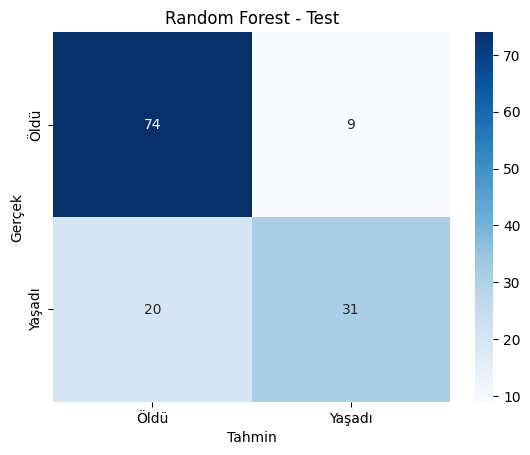

              precision    recall  f1-score   support

        Öldü       0.79      0.89      0.84        83
      Yaşadı       0.78      0.61      0.68        51

    accuracy                           0.78       134
   macro avg       0.78      0.75      0.76       134
weighted avg       0.78      0.78      0.78       134



In [31]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

test_tahmin = orman.predict(X_test)

cm = confusion_matrix(y_test, test_tahmin)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Öldü", "Yaşadı"],
            yticklabels=["Öldü", "Yaşadı"])
plt.xlabel("Tahmin")
plt.ylabel("Gerçek")
plt.title("Random Forest - Test")
plt.show()

print(classification_report(y_test, test_tahmin, target_names=["Öldü", "Yaşadı"]))